In [3]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
Available GPUs: []


2026-10-26 04:22:52.243905: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)
    if level <= 3:
        print(root, "| folders:", dirs[:8], "| files:", len(files))

/kaggle/input | folders: ['datasets'] | files: 0
/kaggle/input/datasets | folders: ['anasmohammedtahir'] | files: 0
/kaggle/input/datasets/anasmohammedtahir | folders: ['covidqu'] | files: 0
/kaggle/input/datasets/anasmohammedtahir/covidqu | folders: ['Infection Segmentation Data', 'Lung Segmentation Data'] | files: 1


In [5]:
import os

base_path = "/kaggle/input/datasets/anasmohammedtahir/covidqu"

for folder in ["Infection Segmentation Data", "Lung Segmentation Data"]:
    path = os.path.join(base_path, folder)
    print(f"\n--- {folder} ---")

    for root, dirs, files in os.walk(path):
        level = root.replace(path, "").count(os.sep)
        if level <= 2:
            print("  " * level, os.path.basename(root),
                  "| subfolders:", dirs[:6],
                  "| files:", len(files))


--- Infection Segmentation Data ---
 Infection Segmentation Data | subfolders: ['Infection Segmentation Data'] | files: 0
   Infection Segmentation Data | subfolders: ['Test', 'Train', 'Val'] | files: 0
     Test | subfolders: ['COVID-19', 'Non-COVID', 'Normal'] | files: 0
     Train | subfolders: ['COVID-19', 'Non-COVID', 'Normal'] | files: 0
     Val | subfolders: ['COVID-19', 'Non-COVID', 'Normal'] | files: 0

--- Lung Segmentation Data ---
 Lung Segmentation Data | subfolders: ['Lung Segmentation Data'] | files: 0
   Lung Segmentation Data | subfolders: ['Test', 'Train', 'Val'] | files: 0
     Test | subfolders: ['COVID-19', 'Non-COVID', 'Normal'] | files: 0
     Train | subfolders: ['COVID-19', 'Non-COVID', 'Normal'] | files: 0
     Val | subfolders: ['COVID-19', 'Non-COVID', 'Normal'] | files: 0


In [6]:
import os
import tensorflow as tf

data_path = "/kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data"

for split in ["Train", "Val", "Test"]:
    split_path = os.path.join(data_path, split)
    print(f"\n{split}:")
    for class_name in ["COVID-19", "Non-COVID", "Normal"]:
        class_path = os.path.join(split_path, class_name)
        image_count = sum(
            1 for f in os.listdir(class_path)
            if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
        )
        print(f"  {class_name}: {image_count} images")


Train:
  COVID-19: 0 images
  Non-COVID: 0 images
  Normal: 0 images

Val:
  COVID-19: 0 images
  Non-COVID: 0 images
  Normal: 0 images

Test:
  COVID-19: 0 images
  Non-COVID: 0 images
  Normal: 0 images


In [7]:
import os

base_path = "/kaggle/input/datasets/anasmohammedtahir/covidqu"

count = 0

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith(
            (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
        ):
            print(os.path.join(root, file))
            count += 1

            if count >= 20:
                break

    if count >= 20:
        break

print("\nImage files found in sample:", count)

/kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data/Test/COVID-19/images/covid_1579.png
/kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data/Test/COVID-19/images/covid_1582.png
/kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data/Test/COVID-19/images/covid_1583.png
/kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data/Test/COVID-19/images/covid_1584.png
/kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data/Test/COVID-19/images/covid_1585.png
/kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data/Test/COVID-19/images/covid_1586.png
/kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data/Test/COVID-19/images/covid_1587.png
/kaggle/input

In [8]:
import tensorflow as tf
import os

data_path = "/kaggle/input/datasets/anasmohammedtahir/covidqu/Infection Segmentation Data/Infection Segmentation Data"

img_size = (128, 128)
batch_size = 32

train_generator = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_path, "Train"),
    labels="inferred",
    label_mode="categorical",
    class_names=["COVID-19", "Non-COVID", "Normal"],
    image_size=img_size,
    batch_size=batch_size
)

val_generator = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_path, "Val"),
    labels="inferred",
    label_mode="categorical",
    class_names=["COVID-19", "Non-COVID", "Normal"],
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

test_generator = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_path, "Test"),
    labels="inferred",
    label_mode="categorical",
    class_names=["COVID-19", "Non-COVID", "Normal"],
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

print("Classes:", train_generator.class_names)
print("Dataset loaded successfully!")

Found 11184 files belonging to 3 classes.
Found 2796 files belonging to 3 classes.
Found 3498 files belonging to 3 classes.
Classes: ['COVID-19', 'Non-COVID', 'Normal']
Dataset loaded successfully!


In [9]:
base_model_3 = tf.keras.applications.EfficientNetB0(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

base_model_3.trainable = False

model_3 = tf.keras.Sequential([
    base_model_3,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

model_3.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_3.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,926 (16.07 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [10]:
history_3 = model_3.fit(
    train_generator,
    validation_data=val_generator,
    epochs=4,
    steps_per_epoch=100,
    validation_steps=30
)

Epoch 1/4
100/100 ━━━━━━━━━━━━━━━━━━━━ 66s 556ms/step - accuracy: 0.6806 - loss: 0.7140 - val_accuracy: 0.9260 - val_loss: 0.2548
Epoch 2/4
100/100 ━━━━━━━━━━━━━━━━━━━━ 80s 808ms/step - accuracy: 0.7147 - loss: 0.5940 - val_accuracy: 0.9312 - val_loss: 0.2192
Epoch 3/4
100/100 ━━━━━━━━━━━━━━━━━━━━ 49s 487ms/step - accuracy: 0.7391 - loss: 0.5695 - val_accuracy: 0.9521 - val_loss: 0.1623
Epoch 4/4
 50/100 ━━━━━━━━━━━━━━━━━━━━ 18s 377ms/step - accuracy: 0.7461 - loss: 0.5307

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 ━━━━━━━━━━━━━━━━━━━━ 29s 294ms/step - accuracy: 0.7437 - loss: 0.5477 - val_accuracy: 0.9563 - val_loss: 0.1579


In [11]:
base_model_4 = tf.keras.applications.DenseNet121(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

base_model_4.trainable = False

model_4 = tf.keras.Sequential([
    base_model_4,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

model_4.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_4.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,169,091 (27.35 MB)

 Trainable params: 131,587 (514.01 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [12]:
train_repeated = train_generator.repeat()
val_repeated = val_generator.repeat()

history_4 = model_4.fit(
    train_repeated,
    validation_data=val_repeated,
    epochs=4,
    steps_per_epoch=100,
    validation_steps=30
)

Epoch 1/4
100/100 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.5691 - loss: 1.9119 - val_accuracy: 0.7802 - val_loss: 0.5817
Epoch 2/4
100/100 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.6328 - loss: 1.0920 - val_accuracy: 0.7000 - val_loss: 0.7741
Epoch 3/4
100/100 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.6572 - loss: 0.9926 - val_accuracy: 0.9365 - val_loss: 0.1842
Epoch 4/4
100/100 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.6812 - loss: 0.7963 - val_accuracy: 0.8052 - val_loss: 0.5022


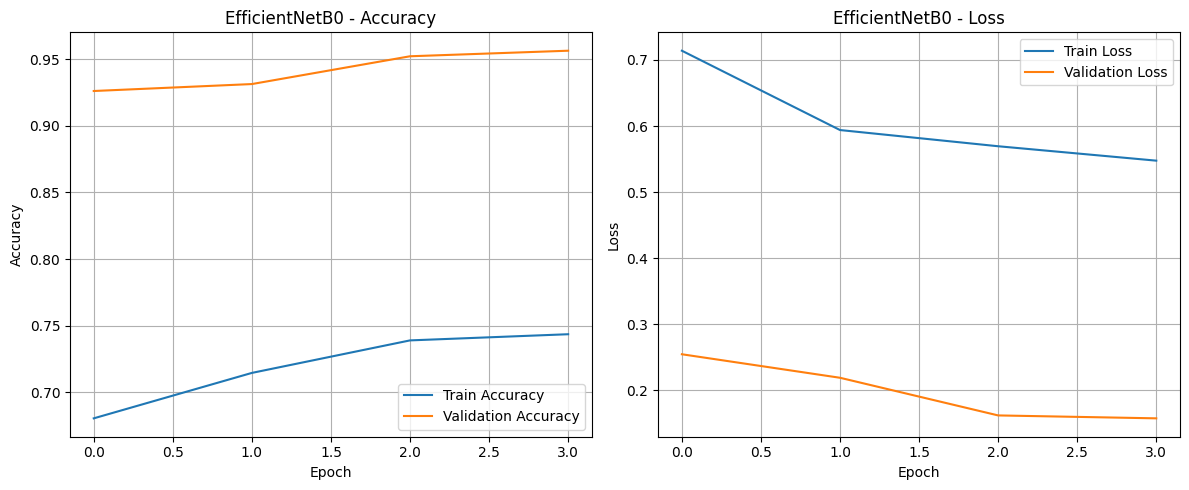

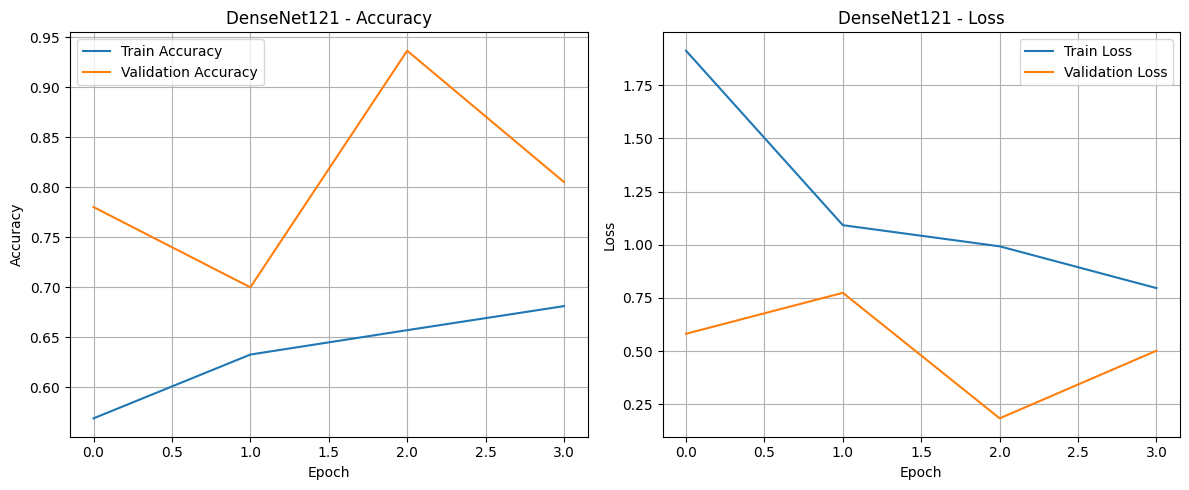

In [13]:
import matplotlib.pyplot as plt

# EfficientNetB0
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_3.history['accuracy'], label='Train Accuracy')
plt.plot(history_3.history['val_accuracy'], label='Validation Accuracy')
plt.title('EfficientNetB0 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_3.history['loss'], label='Train Loss')
plt.plot(history_3.history['val_loss'], label='Validation Loss')
plt.title('EfficientNetB0 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# DenseNet121
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_4.history['accuracy'], label='Train Accuracy')
plt.plot(history_4.history['val_accuracy'], label='Validation Accuracy')
plt.title('DenseNet121 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_4.history['loss'], label='Train Loss')
plt.plot(history_4.history['val_loss'], label='Validation Loss')
plt.title('DenseNet121 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

110/110 ━━━━━━━━━━━━━━━━━━━━ 41s 351ms/step

=============== EfficientNetB0 ===============
              precision    recall  f1-score   support

    COVID-19       0.86      0.93      0.89      1749
   Non-COVID       0.60      0.71      0.65       876
      Normal       0.73      0.48      0.58       873

    accuracy                           0.76      3498
   macro avg       0.73      0.70      0.71      3498
weighted avg       0.76      0.76      0.75      3498



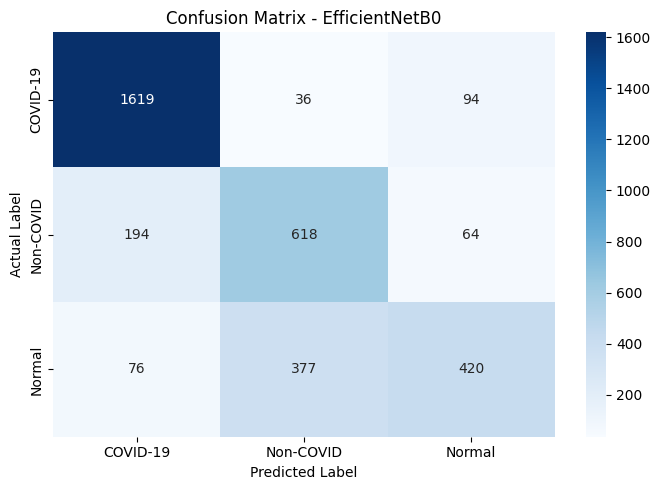

110/110 ━━━━━━━━━━━━━━━━━━━━ 96s 838ms/step

=============== DenseNet121 ===============
              precision    recall  f1-score   support

    COVID-19       0.91      0.66      0.77      1749
   Non-COVID       0.48      0.80      0.60       876
      Normal       0.55      0.48      0.51       873

    accuracy                           0.65      3498
   macro avg       0.64      0.65      0.63      3498
weighted avg       0.71      0.65      0.66      3498



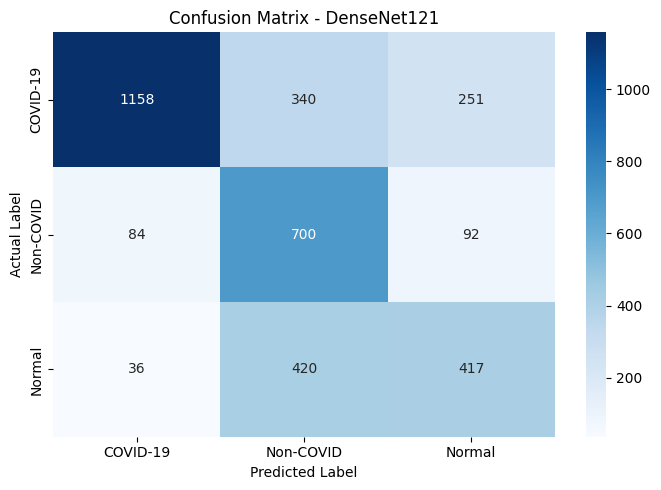

In [14]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# Get actual test labels
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_generator
])

class_labels = test_generator.class_names

def evaluate_model(model, name):
    predictions = model.predict(test_generator, verbose=1)
    y_pred = np.argmax(predictions, axis=1)

    print(f"\n{'=' * 15} {name} {'=' * 15}")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_labels))),
        target_names=class_labels,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_true, y_pred,
        labels=list(range(len(class_labels)))
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.tight_layout()
    plt.show()


evaluate_model(model_3, "EfficientNetB0")
evaluate_model(model_4, "DenseNet121")